In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mgmitesh/plant-disease-detection-dataset/valid/Tomato/Early Blight/a3d07302-420d-4b4e-94f2-6694ef9d2088___RS_Erly.B 7652.JPG
/kaggle/input/datasets/mgmitesh/plant-disease-detection-dataset/valid/Tomato/Early Blight/dc6eeebe-ebc4-406c-b5df-f4861f491db8___RS_Erly.B 9615_180deg.JPG
/kaggle/input/datasets/mgmitesh/plant-disease-detection-dataset/valid/Tomato/Early Blight/bef16984-17c5-4796-9496-85808dfa3a56___RS_Erly.B 9405.JPG
/kaggle/input/datasets/mgmitesh/plant-disease-detection-dataset/valid/Tomato/Early Blight/9744fa97-16b3-4a16-afc0-c86ac0397759___RS_Erly.B 6411_flipTB.JPG
/kaggle/input/datasets/mgmitesh/plant-disease-detection-dataset/valid/Tomato/Early Blight/e332b0b1-ed0c-49b0-aad2-da29a8636126___RS_Erly.B 9418.JPG
/kaggle/input/datasets/mgmitesh/plant-disease-detection-dataset/valid/Tomato/Early Blight/a8b2bbbc-5bef-4ef4-8322-48cde639a9aa___RS_Erly.B 7438_flipTB.JPG
/kaggle/input/datasets/mgmitesh/plant-disease-detection-dataset/valid/Tomato/Early Blight/8

In [2]:

import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 20  # Initial comparison; increase later if needed

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [3]:

DATA_ROOT = Path("/kaggle/input/datasets/mgmitesh/plant-disease-detection-dataset")

train_candidates = [
    p for p in DATA_ROOT.rglob("train")
    if p.is_dir()
    and (p.parent / "valid").is_dir()
    and (p.parent / "test").is_dir()
]

if not train_candidates:
    raise FileNotFoundError(
        "train/valid/test folders nahi mile. "
        "Check karo ke dataset Kaggle mein Add Input se attach hai."
    )

TRAIN_DIR = train_candidates[0]
DATASET_DIR = TRAIN_DIR.parent
VALID_DIR = DATASET_DIR / "valid"
TEST_DIR = DATASET_DIR / "test"

class_names = sorted([
    p.name for p in TRAIN_DIR.iterdir()
    if p.is_dir()
])

NUM_CLASSES = len(class_names)

print("Dataset:", DATASET_DIR)
print("Classes:", NUM_CLASSES)
print(class_names)

print("Train class folders:", len(list(TRAIN_DIR.iterdir())))
print("Valid class folders:", len(list(VALID_DIR.iterdir())))
print("Test class folders:", len(list(TEST_DIR.iterdir())))

with open("/kaggle/working/class_names.json", "w") as f:
    json.dump(class_names, f, indent=2)


Dataset: /kaggle/input/datasets/mgmitesh/plant-disease-detection-dataset
Classes: 9
['Apple', 'Cherry', 'Corn', 'Grape', 'Peach', 'Pepper', 'Potato', 'Strawberry', 'Tomato']
Train class folders: 9
Valid class folders: 9
Test class folders: 39


In [4]:
from pathlib import Path

for split in ["train", "valid"]:
    split_path = DATA_ROOT / split

    print(f"\n{split.upper()} DATASET")

    for plant_folder in sorted(split_path.iterdir()):
        if plant_folder.is_dir():
            diseases = [
                d.name for d in sorted(plant_folder.iterdir())
                if d.is_dir()
            ]
            print(plant_folder.name, ":", diseases)


TRAIN DATASET
Apple : ['Apple Scab', 'Black Rot', 'Cedar Apple Rust', 'Healthy']
Cherry : ['Healthy', 'Powdery Mildew']
Corn : ['Common Rust', 'Gray Leaf Spot', 'Healthy', 'Northern Leaf Blight']
Grape : ['Black Rot', 'Esca', 'Healthy', 'Leaf Blight']
Peach : ['Bacterial Spot', 'Healthy']
Pepper : ['Bacterial Spot', 'Healthy']
Potato : ['Early Blight', 'Healthy', 'Late Blight']
Strawberry : ['Healthy', 'Leaf Scorch']
Tomato : ['Bacterial Spot', 'Early Blight', 'Healthy', 'Late Blight']

VALID DATASET
Apple : ['Apple Scab', 'Black Rot', 'Cedar Apple Rust', 'Healthy']
Cherry : ['Healthy', 'Powdery Mildew']
Corn : ['Common Rust', 'Gray Leaf Spot', 'Healthy', 'Northern Leaf Blight']
Grape : ['Black Rot', 'Esca', 'Healthy', 'Leaf Blight']
Peach : ['Bacterial Spot', 'Healthy']
Pepper : ['Bacterial Spot', 'Healthy']
Potato : ['Early Blight', 'Healthy', 'Late Blight']
Strawberry : ['Healthy', 'Leaf Scorch']
Tomato : ['Bacterial Spot', 'Early Blight', 'Healthy', 'Late Blight']


In [5]:

import tensorflow as tf
from pathlib import Path
import numpy as np

# Dataset paths
TRAIN_DIR = DATA_ROOT / "train"
VALID_DIR = DATA_ROOT / "valid"

# Settings
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Collect images with their full disease labels
def collect_images(split_dir):
    file_paths = []
    labels = []

    for plant_dir in sorted(split_dir.iterdir()):
        if not plant_dir.is_dir():
            continue

        for disease_dir in sorted(plant_dir.iterdir()):
            if not disease_dir.is_dir():
                continue

            for img_path in disease_dir.iterdir():
                if img_path.suffix.lower() in [
                    ".jpg", ".jpeg", ".png", ".bmp"
                ]:
                    file_paths.append(str(img_path))
                    labels.append(f"{plant_dir.name} - {disease_dir.name}")

    return file_paths, labels


train_paths, train_labels = collect_images(TRAIN_DIR)
valid_paths, valid_labels = collect_images(VALID_DIR)

# Consistent class mapping across both splits
class_names = sorted(set(train_labels) | set(valid_labels))
class_to_index = {name: i for i, name in enumerate(class_names)}

y_train = np.array([class_to_index[x] for x in train_labels])
y_valid = np.array([class_to_index[x] for x in valid_labels])

NUM_CLASSES = len(class_names)

print("Number of classes:", NUM_CLASSES)
print("Training images:", len(train_paths))
print("Validation images:", len(valid_paths))
print("\nClass names:")
for i, name in enumerate(class_names):
    print(i, name)

# Load and preprocess images
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=min(len(paths), 10000),
            seed=SEED
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_paths, y_train, training=True)
val_ds = make_dataset(valid_paths, y_valid)

print("\nDatasets prepared successfully!")
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())


Number of classes: 27
Training images: 49984
Validation images: 12494

Class names:
0 Apple - Apple Scab
1 Apple - Black Rot
2 Apple - Cedar Apple Rust
3 Apple - Healthy
4 Cherry - Healthy
5 Cherry - Powdery Mildew
6 Corn - Common Rust
7 Corn - Gray Leaf Spot
8 Corn - Healthy
9 Corn - Northern Leaf Blight
10 Grape - Black Rot
11 Grape - Esca
12 Grape - Healthy
13 Grape - Leaf Blight
14 Peach - Bacterial Spot
15 Peach - Healthy
16 Pepper - Bacterial Spot
17 Pepper - Healthy
18 Potato - Early Blight
19 Potato - Healthy
20 Potato - Late Blight
21 Strawberry - Healthy
22 Strawberry - Leaf Scorch
23 Tomato - Bacterial Spot
24 Tomato - Early Blight
25 Tomato - Healthy
26 Tomato - Late Blight


I0000 00:00:1792082078.486334      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792082078.490925      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



Datasets prepared successfully!
Training batches: 1562
Validation batches: 391


In [6]:

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# Build CNN model
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(256, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = callbacks.ModelCheckpoint(
    "/kaggle/working/best_plant_disease_model.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop, checkpoint]
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 27)             │         3,483 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,795 (1.62 MB)

 Trainable params: 424,795 (1.62 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
   2/1562 ━━━━━━━━━━━━━━━━━━━━ 2:01 78ms/step - accuracy: 0.0391 - loss: 3.2743      

I0000 00:00:1792082091.987111      70 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1562/1562 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.3352 - loss: 1.9751
Epoch 1: val_loss improved from None to 2.24387, saving model to /kaggle/working/best_plant_disease_model.keras

Epoch 1: finished saving model to /kaggle/working/best_plant_disease_model.keras
1562/1562 ━━━━━━━━━━━━━━━━━━━━ 115s 67ms/step - accuracy: 0.3716 - loss: 2.0333 - val_accuracy: 0.3890 - val_loss: 2.2439
Epoch 2/20
1562/1562 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.6447 - loss: 1.1137
Epoch 2: val_loss improved from 2.24387 to 1.63122, saving model to /kaggle/working/best_plant_disease_model.keras

Epoch 2: finished saving model to /kaggle/working/best_plant_disease_model.keras
1562/1562 ━━━━━━━━━━━━━━━━━━━━ 98s 63ms/step - accuracy: 0.6504 - loss: 1.1029 - val_accuracy: 0.5550 - val_loss: 1.6312
Epoch 3/20
1562/1562 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.7744 - loss: 0.6871
Epoch 3: val_loss improved from 1.63122 to 1.27641, saving model to /kaggle/working/best_plant_disease_model.k

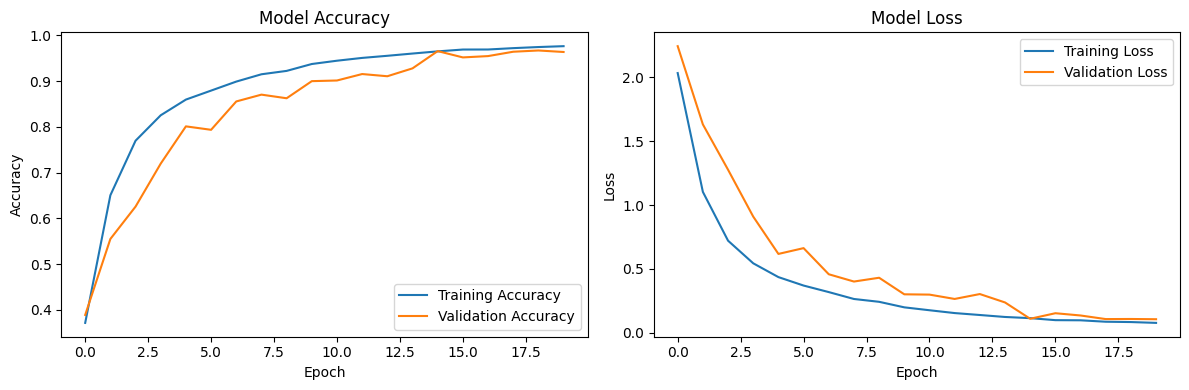

In [7]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [8]:

best_model = tf.keras.models.load_model(
    "/kaggle/working/best_plant_disease_model.keras"
)

best_model_name = "Custom CNN"

val_loss, val_accuracy = best_model.evaluate(val_ds, verbose=1)

print("Best model:", best_model_name)
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")
print(f"Validation Loss: {val_loss:.4f}")


391/391 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9634 - loss: 0.1059
Best model: Custom CNN
Validation Accuracy: 96.34%
Validation Loss: 0.1059


391/391 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step
Best model: Custom CNN

Classification Report:

                             precision    recall  f1-score   support

         Apple - Apple Scab     1.0000    0.9087    0.9522       504
          Apple - Black Rot     0.9776    0.9678    0.9727       497
   Apple - Cedar Apple Rust     0.9976    0.9386    0.9672       440
            Apple - Healthy     0.9908    0.8606    0.9211       502
           Cherry - Healthy     0.9911    0.9715    0.9812       456
    Cherry - Powdery Mildew     0.9974    0.9000    0.9462       420
         Corn - Common Rust     0.9978    0.9371    0.9665       477
      Corn - Gray Leaf Spot     0.9913    0.8341    0.9060       410
             Corn - Healthy     0.9936    0.9978    0.9957       465
Corn - Northern Leaf Blight     0.8640    0.9853    0.9207       477
          Grape - Black Rot     1.0000    0.9492    0.9739       472
               Grape - Esca     0.9795    0.9958    0.9876       480
           

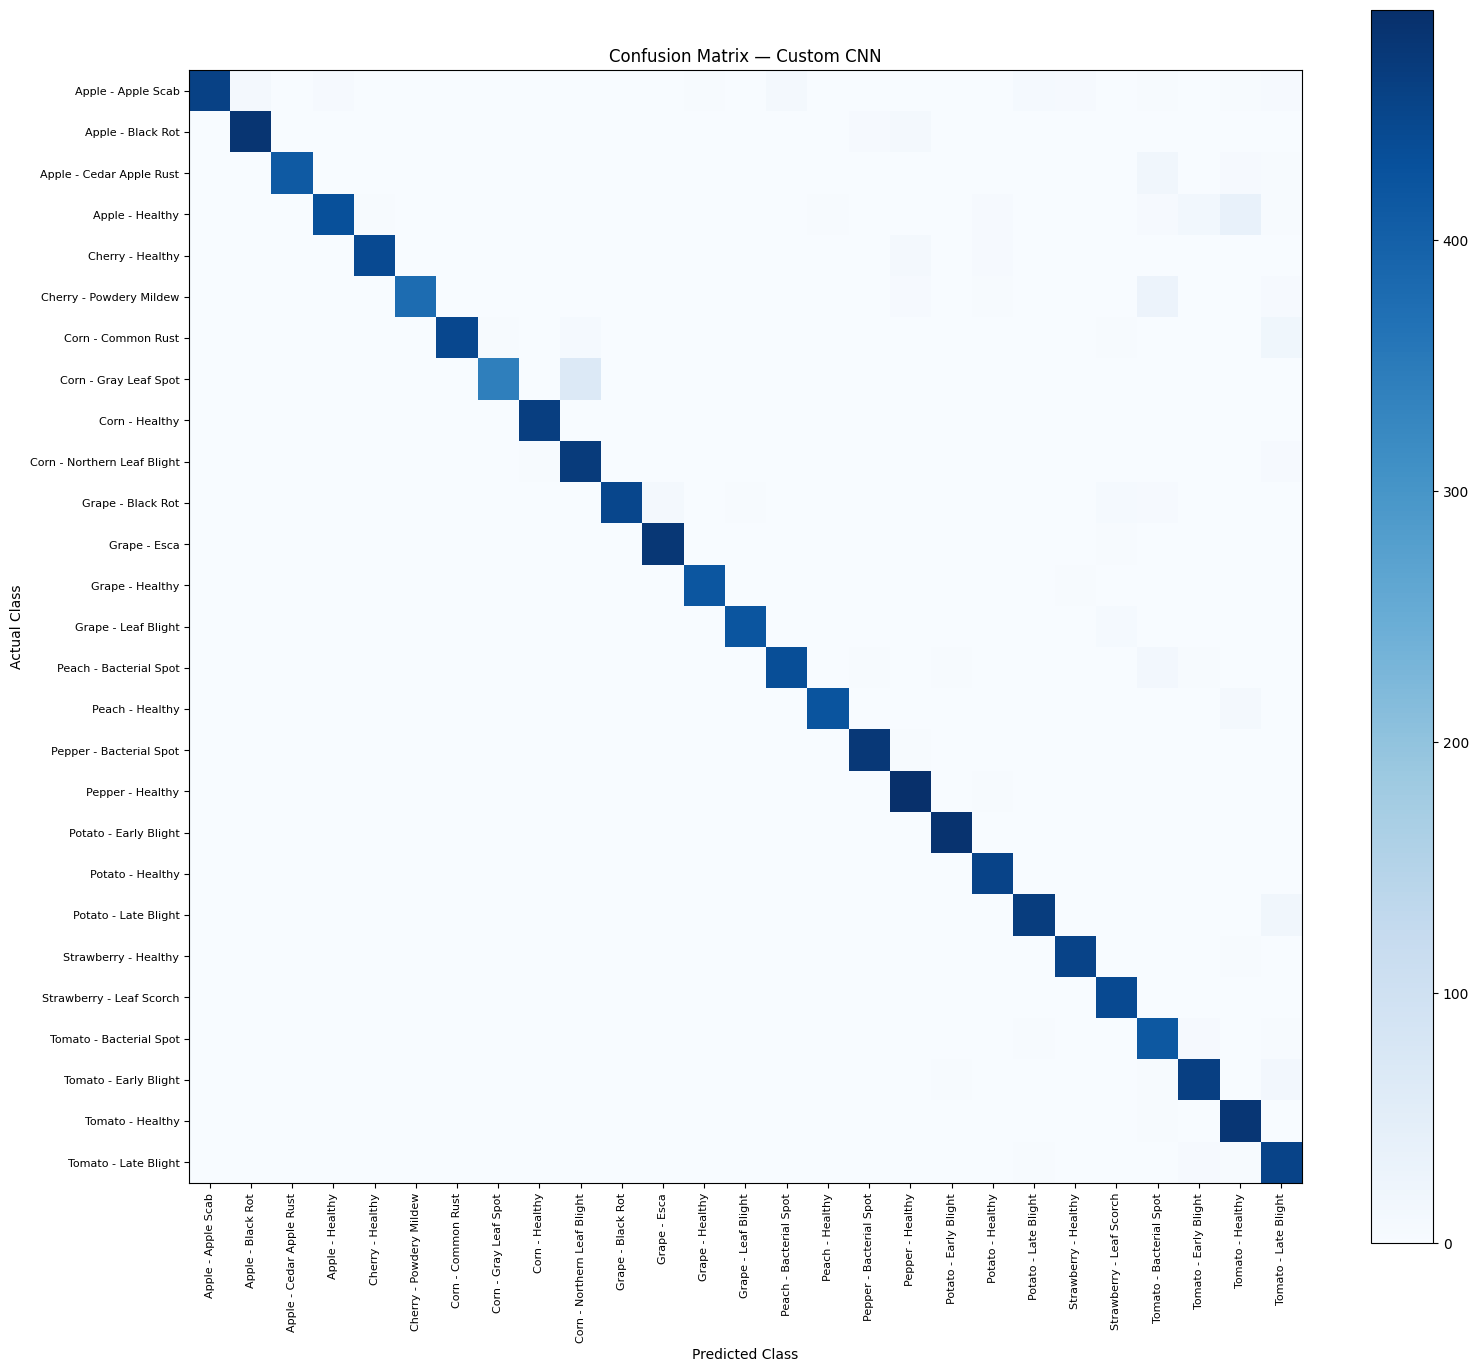

In [9]:

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

# Actual labels from validation dataset
y_true = np.concatenate([
    labels.numpy() for _, labels in val_ds
])

# Model predictions
y_prob = best_model.predict(val_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("Best model:", best_model_name)
print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    zero_division=0,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(16, 14))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.colorbar()
plt.xticks(
    np.arange(NUM_CLASSES),
    class_names,
    rotation=90,
    fontsize=8
)
plt.yticks(
    np.arange(NUM_CLASSES),
    class_names,
    fontsize=8
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


In [10]:

import json
import os

# 1. Save trained model
MODEL_PATH = "/kaggle/working/plant_disease_model.keras"
best_model.save(MODEL_PATH)

# 2. Save class names
CLASS_PATH = "/kaggle/working/class_names.json"

with open(CLASS_PATH, "w") as f:
    json.dump(class_names, f, indent=4)

# 3. Verify both files
print("Model saved:", os.path.exists(MODEL_PATH))
print("Class names saved:", os.path.exists(CLASS_PATH))


Model saved: True
Class names saved: True


In [11]:
import os

print(os.listdir("/kaggle/working"))

['class_names.json', 'best_plant_disease_model.keras', 'plant_disease_model.keras', '__notebook__.ipynb']


In [12]:

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VALID_DIR,
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

# Show sample images
images, labels = next(iter(train_ds))

plt.figure(figsize=(10, 6))
for i in range(min(6, len(images))):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[int(labels[i])])
    plt.axis("off")

plt.tight_layout()
plt.show()


ValueError: The `class_names` passed did not match the names of the subdirectories of the target directory. Expected: ['Apple', 'Cherry', 'Corn', 'Grape', 'Peach', 'Pepper', 'Potato', 'Strawberry', 'Tomato'] (or a subset of it), but received: class_names=['Apple - Apple Scab', 'Apple - Black Rot', 'Apple - Cedar Apple Rust', 'Apple - Healthy', 'Cherry - Healthy', 'Cherry - Powdery Mildew', 'Corn - Common Rust', 'Corn - Gray Leaf Spot', 'Corn - Healthy', 'Corn - Northern Leaf Blight', 'Grape - Black Rot', 'Grape - Esca', 'Grape - Healthy', 'Grape - Leaf Blight', 'Peach - Bacterial Spot', 'Peach - Healthy', 'Pepper - Bacterial Spot', 'Pepper - Healthy', 'Potato - Early Blight', 'Potato - Healthy', 'Potato - Late Blight', 'Strawberry - Healthy', 'Strawberry - Leaf Scorch', 'Tomato - Bacterial Spot', 'Tomato - Early Blight', 'Tomato - Healthy', 'Tomato - Late Blight']